# Discovering an Active Subspace in a Single-Diode Solar Cell Model

__Paul G. Constantine__ and __Brian Zaharatos__, Department of Applied Mathematics and Statistics, Colorado School of Mines

__Mark Campanelli__, National Renewable Energy Laboratory

__Ryan Howard__, Colorado School of Mines (2016 notebook)

<br>

This notebook summarizes the active subspaces methodology and its results on a single-diode solar cell model presented in [[1]][R1], and reproduces the paper's analysis (§4) with the [active_subspaces](https://github.com/paulcon/active_subspaces) library, version 1.0 or later. It runs in Python 3 with numpy, scipy and matplotlib (see the repository's `requirements.txt`), and takes about 10 seconds.

### Introduction

Scientific and engineering models will usually contain input parameters (physical constants, geometric specifications, etc.), and important questions about the model's output often require characterizing the relationship between the output and the input parameters. Intuition about the physical system can become unreliable as models grow in complexity and the required number of model evaluations for parameter studies grows exponentially with increasing dimension. One solution to these issues is dimension reduction: using low-dimensional structure to perform parameter studies.

### Active Subspaces

_Active Subspaces_ is a method of dimension reduction that identifies important directions in the input space, along which perturbations in inputs change the output more than in the orthogonal directions. We consider the model's output, $f$, as a function of the normalized input parameters, $\mathbf x$: $f = f(\mathbf x)$. The active subspaces methodology is based on the matrix

$$
\mathbf C = \int\nabla f(\mathbf x)\nabla f(\mathbf x)^T \rho(\mathbf x)\ d\mathbf x = \mathbf W \Lambda\mathbf W^T,
$$

where $\rho$ is a probability density on $\mathbf x$ and $\mathbf W \Lambda\mathbf W^T$ is the eigendecomposition of $\mathbf C$ (the diagonal of $\Lambda$ contains the eigenvalues of $\mathbf C$ in descending order, and $\mathbf W$'s columns contain the corresponding eigenvectors). We can partition the decomposition:

$$
\mathbf W = \left[\begin{matrix}\mathbf W_1 & \mathbf W_2\end{matrix}\right],\ \Lambda = \left[\begin{matrix} \Lambda_1 & \\ & \Lambda_2\end{matrix}\right],
$$

where $\mathbf W_1$ contains the first $n$ eigenvectors and $\Lambda_1$ contains the first $n$ eigenvalues (this decomposition will be valid so long as $\lambda_n > \lambda_{n+1}$). The active subspace is the space spanned by $\mathbf W_1$ and the active variables are $\mathbf y = \mathbf W_1^T\mathbf x$. The amount $f$ tends to change along the direction defined by the eigenvector $\mathbf w_i$ is $\int(\nabla f^T\mathbf w_i)^2\rho\, d\mathbf x = \lambda_i$, and the amount $f$ tends to change along the active subspace is $\int(\nabla_{\mathbf y}f)^T(\nabla_{\mathbf y}f)\rho\, d\mathbf x = \lambda_1 + \cdots + \lambda_n$. If an eigenvalue were exactly zero, $f$ would be exactly constant along the corresponding eigenvector; in practice, the first several eigenvalues will be much larger than the later values (though they are nonzero), so $f$ could be reasonably examined in this low dimensional subspace.

To identify an active subspace, we approximate $\mathbf C$ with simple Monte Carlo: draw $\{\mathbf x_i\}_{i=1}^M$ from $\rho$, then

$$
\mathbf C\approx\mathbf{\hat C} = \frac 1 M\sum_{i=1}^M \nabla f(\mathbf x_i)\nabla f(\mathbf x_i)^T = \mathbf{\hat W}\hat\Lambda\mathbf{\hat W}^T.
$$

The error in the estimated subspace, $\|\mathbf W_1\mathbf W_1^T - \mathbf{\hat W}_1\mathbf{\hat W}_1^T\|_2$, is bounded by a quantity proportional to $1/(\lambda_n-\lambda_{n+1})$ [[2]][R2], so a large gap gives an accurate subspace, and large gaps in eigenvalue magnitudes are what we use to identify the active subspace. We can use a bootstrap procedure to estimate the variability in the eigenvalues/vectors: for $j$ from 1 to $M'$, let $\pi^j$ be an $M$-vector of integers sampled uniformly between 1 and $M$. The $j^{th}$ bootstrap replicate of $\mathbf{\hat C}$ is

$$
\mathbf{\hat C}^j = \frac 1 M\sum_{i=1}^M\nabla f(\mathbf x_{\pi_i^j})\nabla f(\mathbf x_{\pi_i^j})^T = \mathbf{\hat W}^j\hat\Lambda^j(\mathbf{\hat W}^j)^T.
$$

The subspace error of the $j^{th}$ replicate is $e_j = \|\mathbf{\hat W}_1^T\mathbf{\hat W}_2^j\|_2$ ([[1]][R1] eq. (8)), the sine of the largest principal angle between the subspaces spanned by $\mathbf{\hat W}_1$ and $\mathbf{\hat W}_1^j$.

When the gradient of $f$ is not known analytically, it must be approximated; the data used here have first-order finite-difference gradients with a step of $10^{-6}$ in the normalized coordinates ([[1]][R1] §4.2). Important to note is that our solar cell model does not take long to run, even on home PC's. If we had a model that was very expensive, taking hours to run on HPC platforms, strategies for choosing model evaluation points and approximating gradients would have to be altered to fit within the limited computational budget.

### The solar cell model

We use active subspaces to analyze a single-diode solar cell model that well describes the current-voltage (I-V) relationship of many series-wired photovoltaic (PV) devices. The equation governing I and V is

$$
I = I_L - I_S\left(\exp\left(\frac{V+IR_S}{N_SnV_{th}}\right) - 1\right) - \frac{V+IR_S}{R_P},
$$

where

$$
I_L = I_{SC}+I_S\left(\exp\left(\frac{I_{SC}R_S}{N_SnV_{th}}\right)-1\right)+\frac{I_{SC}R_S}{R_P}.
$$

$N_S$ is the number of series-connected cells (we set this to 1) and $V_{th} = k_BT/q$ is the thermal voltage at the fixed temperature $T = 25^\circ$C, $V_{th} \approx 0.025693$ V. ([[1]][R1] gives no value for $V_{th}$; this one reproduces the stored data, as checked below.) The rest of the parameters are input parameters of the model, and their ranges and densities are summarized in the table below ([[1]][R1] Table 1).

Variable | Lower bound | Upper bound | Units | Density
--- | --- | --- | --- | ---
Short-circuit current, $I_{SC}$ | 0.05989 | 0.23958 | A | Uniform
Diode reverse saturation current, $I_S$ | 2.2e-11 | 2.2e-7 | A | Log-uniform
Ideality factor, $n$ | 1 | 2 | (none) | Uniform
Series resistance, $R_S$ | 0.16625 | 0.66500 | Ω | Uniform
Parallel (shunt) resistance, $R_P$ | 93.75 | 375 | Ω | Uniform

The quantity of interest we want to examine is the maximum power output of the cell: $P_{max} = \max\limits_{I,V}\ IV$ [W], where I and V are constrained by the equations presented above.

**A note on [[1]][R1].** Two statements in the paper are corrected above. On p. 266 the eigenvalue gap is written $\lambda_{n+1}-\lambda_n$, and the subspace distance is said to be inversely proportional to it; the gap is $\lambda_n-\lambda_{n+1}$, and the distance is bounded by a quantity proportional to its inverse. On p. 269 the subspace error (8) is called the cosine of the principal angle between the subspaces; it is the sine of the largest principal angle.

### References:

[[1]][R1] P.G. Constantine, B. Zaharatos, and M. Campanelli. _Discovering an active subspace in a single-diode solar cell model_. Stat. Anal. Data Min.: The ASA Data Sci. J., 8(5–6):264–273, 2015. doi:10.1002/sam.11281 (open copy: [arXiv:1406.7607](https://arxiv.org/abs/1406.7607))

[[2]][R2] P.G. Constantine, E. Dow, and Q. Wang. _Active subspace methods in theory and practice: applications to kriging surfaces_. SIAM J. Sci. Comput., 36(4):A1500–A1524, 2014. doi:10.1137/130916138

[R1]: https://doi.org/10.1002/sam.11281
[R2]: https://doi.org/10.1137/130916138

### Acknowledgments

This material is based upon work supported by the U.S. Department of Energy Office of Science, Office of Advanced Scientific Computing Research, Applied Mathematics program under Award Number DE-SC-0011077.

<br>

We'll now code up the analysis using the [active_subspaces](https://github.com/paulcon/active_subspaces) library.

In [1]:
%matplotlib inline
import time

import numpy as np
import matplotlib.pyplot as plt
import active_subspaces as ac
import single_diode as sd

t_start = time.perf_counter()
rng = np.random.default_rng(2016)   # the only source of randomness in this notebook

Load the data set, which contains 10,000 sets of input parameters and the corresponding $P_{max}$ values with gradients. Campanelli's MATLAB code computed them ([[1]][R1] §3.1); it is not in this repository, so the file is the record of those runs (see `DATA.md`). The inputs are stored in physical units. The gradients are with respect to the normalized inputs defined below, with $I_S$ through $\log I_S$. Distinguish inputs (X), outputs (f), and gradients (G).

[R1]: https://doi.org/10.1002/sam.11281

In [2]:
rec = np.genfromtxt('SingleDiodePV-Pmax.txt', delimiter=',', names=True)
cols = ['ISC', 'IS', 'n', 'RS', 'RP']
X = np.column_stack([rec[c] for c in cols])         # physical inputs
f = rec['Pmax']                                      # P_max [W]
G = np.column_stack([rec['d' + c] for c in cols])   # dP_max/dx, x normalized (log I_S)
M, m = X.shape
print(f'{M} samples of {m} inputs; P_max from {f.min():.4f} to {f.max():.4f} W')

10000 samples of 5 inputs; P_max from 0.0143 to 0.2032 W


Normalize the inputs to the interval [-1,1]. The second variable is uniform in the log space, so we work with the coordinates $(I_{SC}, \log I_S, n, R_S, R_P)$, which are uniform on the box of the Table 1 bounds, and declare that box as the input space. (The 2016 version of this notebook had a typo in the upper bound of $I_{SC}$, 0.23598 instead of 0.23958, which put normalized $I_{SC}$ values above 1 in its summary plots; its eigenvalues and eigenvectors were not affected.)

The stored gradients are already with respect to the normalized inputs. active_subspaces expects gradients with respect to the physical inputs and applies the chain-rule factor $(x_u - x_l)/2$ itself, so we divide the stored gradients by that factor first. Passing them unchanged would scale them twice and give a wrong first eigenvector, dominated by $R_P$.

In [3]:
xl = np.array([0.05989, np.log(2.2e-11), 1.0, 0.16625, 93.75])   # Table 1 bounds on
xu = np.array([0.23958, np.log(2.2e-7), 2.0, 0.665, 375.0])      # (I_SC, log I_S, n, R_S, R_P)
assert np.array_equal(xl, sd.XL) and np.array_equal(xu, sd.XU)
space = ac.Uniform(lower=xl, upper=xu, names=['I_SC', 'log I_S', 'n', 'R_S', 'R_P'])

Xt = X.copy()
Xt[:, 1] = np.log(X[:, 1])        # inputs in the coordinates of the space
G_phys = G / ((xu - xl) / 2)      # undo the normalization; active_subspaces re-applies it
Xn = space.to_normalized(Xt)
assert np.all(np.abs(Xn) <= 1)
print(f'normalized inputs lie in [{Xn.min():.5f}, {Xn.max():.5f}]')

normalized inputs lie in [-0.99998, 0.99995]


Before using the stored data, we check them against `single_diode.py`, a Python re-implementation of the model in this directory. It solves the I-V equation for $I$ explicitly with the Lambert W function, and finds $P_{max}$ by a bounded search for the maximum of $VI$ over $[0, V_{oc}]$. We recompute $P_{max}$ at all 10,000 samples, and the gradient by central differences (step $10^{-6}$ in the normalized coordinates) at 20 random samples.

In [4]:
f_py = np.array([sd.pmax(p) for p in X])
rel_f = f_py / f - 1

rows = rng.choice(M, size=20, replace=False)
h = 1e-6
G_py = np.empty((len(rows), m))
for k, i in enumerate(rows):
    x = sd.to_normalized(X[i])
    G_py[k] = [(sd.pmax(sd.to_physical(x + h*e)) - sd.pmax(sd.to_physical(x - h*e))) / (2*h)
               for e in np.eye(m)]
rel_g = G_py / G[rows] - 1

print(f'V_th = {sd.thermal_voltage(25.0):.6f} V')
print(f'P_max at all {M} samples: relative difference from {rel_f.min():.1e} to {rel_f.max():.1e}')
print('gradient at 20 samples, relative difference:')
for name, mean, worst in zip(space.names, rel_g.mean(axis=0), np.abs(rel_g).max(axis=0)):
    print(f'  d/d{name:8} mean {mean:9.1e}   max |.| {worst:8.1e}')

V_th = 0.025693 V
P_max at all 10000 samples: relative difference from -1.6e-06 to -9.6e-07
gradient at 20 samples, relative difference:
  d/dI_SC     mean   4.7e-05   max |.|  4.8e-05
  d/dlog I_S  mean  -1.1e-06   max |.|  2.2e-06
  d/dn        mean  -1.0e-06   max |.|  1.6e-06
  d/dR_S      mean   3.6e-08   max |.|  6.0e-06
  d/dR_P      mean  -2.0e-06   max |.|  2.7e-06


The re-implementation reproduces the stored $P_{max}$ to a relative $1.6\times 10^{-6}$, and four of the five gradient components to a relative $6\times 10^{-6}$. This confirms that the stored gradients are with respect to the normalized inputs, with $I_S$ in log space. The $I_{SC}$ component differs by a nearly constant relative amount, $4.7\times 10^{-5}$, at every sample checked. Its cause is unknown; it is consistent with the original code using slightly different $I_{SC}$ bounds than Table 1. It is far smaller than the bootstrap variability below, and we use the stored gradients as they are.

Now compute the active subspace from all 10,000 gradients, with 500 bootstrap replicates, as the 2016 notebook did. Eigenvector signs are arbitrary; we make the first component of $\mathbf w_1$ and $\mathbf w_2$ positive, as in [[1]][R1] (for these data this is also active_subspaces' default rule, which makes the largest component positive). We check that the eigenvalues equal those of $\mathbf{\hat C}$ computed directly from the stored gradients, and that $\mathbf w_1$ equals the 2016 notebook's printed values.

[R1]: https://doi.org/10.1002/sam.11281

In [5]:
first_positive = np.eye(m)[:, [0, 0]]   # reference directions: make w_1[0] and w_2[0] positive
sub_all = ac.active_subspace(grads=G_phys, space=space, nboot=500, bootstrap_vectors=2, rng=rng)
sub_all = ac.orient(sub_all, by='reference', reference=first_positive, columns=2)

lam = sub_all.eigenvalues
assert np.allclose(lam, np.linalg.eigvalsh(G.T @ G / M)[::-1], rtol=1e-12, atol=0)
w1_2016 = np.array([0.7674, -0.4228, 0.473, -0.09064, 0.0207])   # printed by the 2016 notebook
assert np.allclose(sub_all.W[:, 0], w1_2016, atol=1e-4)

print('eigenvalues, all 10,000 samples:', np.array2string(lam, precision=4))
print(f'lambda_1/lambda_2 = {lam[0]/lam[1]:.1f}, lambda_2/lambda_3 = {lam[1]/lam[2]:.1f}')
print('w_1 =', np.array2string(sub_all.W[:, 0], precision=4))
print('w_2 =', np.array2string(sub_all.W[:, 1], precision=4))
box = ac.bootstrap_interval(sub_all.bootstrap_eigenvectors[:, :, 0], kind='minmax')
print(f'500 replicates: widest min/max range of a w_1 component {np.max(box[1] - box[0]):.4f}, '
      f'mean subspace distance for n = 1: {ac.mean_distance(sub_all)[0]:.1e}')

eigenvalues, all 10,000 samples: [3.3350e-03 1.7227e-04 2.1552e-05 1.3414e-06 3.9520e-07]
lambda_1/lambda_2 = 19.4, lambda_2/lambda_3 = 8.0
w_1 = [ 0.7674 -0.4228  0.473  -0.0906  0.0207]
w_2 = [ 0.6346  0.429  -0.6074  0.2088  0.0288]
500 replicates: widest min/max range of a w_1 component 0.0088, mean subspace distance for n = 1: 2.2e-03


The paper's figures use $M = 1000$ samples, $M' = 1000$ bootstrap replicates and 99% bootstrap intervals ([[1]][R1] §4.2). To compare with them, we draw 1000 of the 10,000 samples at random and repeat the analysis with those settings. Plot eigenvalues, subspace errors, and eigenvectors, all with their 99% percentile bootstrap intervals (compare with Figures 2 and 3 of [[1]][R1]). The dotted lines mark the dimension $n$ that active_subspaces' default rule picks from the largest gap.

[R1]: https://doi.org/10.1002/sam.11281

M = 1000 samples, 1000 replicates, 99% intervals; dimension n = 1
 k   eigenvalue   interval                  mean subspace distance
 1   3.346e-03    [3.210e-03, 3.501e-03]   7.1e-03
 2   1.800e-04    [1.644e-04, 1.958e-04]   1.1e-02
 3   2.043e-05    [1.799e-05, 2.277e-05]   8.0e-03
 4   1.163e-06    [8.413e-07, 1.492e-06]   2.4e-02
 5   4.242e-07    [3.595e-07, 4.951e-07]   
w_1 = [ 0.7698 -0.4236  0.4683 -0.0904  0.0201] widest 99% interval of a component 0.027
w_2 = [ 0.6328  0.4474 -0.5965  0.2073  0.0239] widest 99% interval of a component 0.055


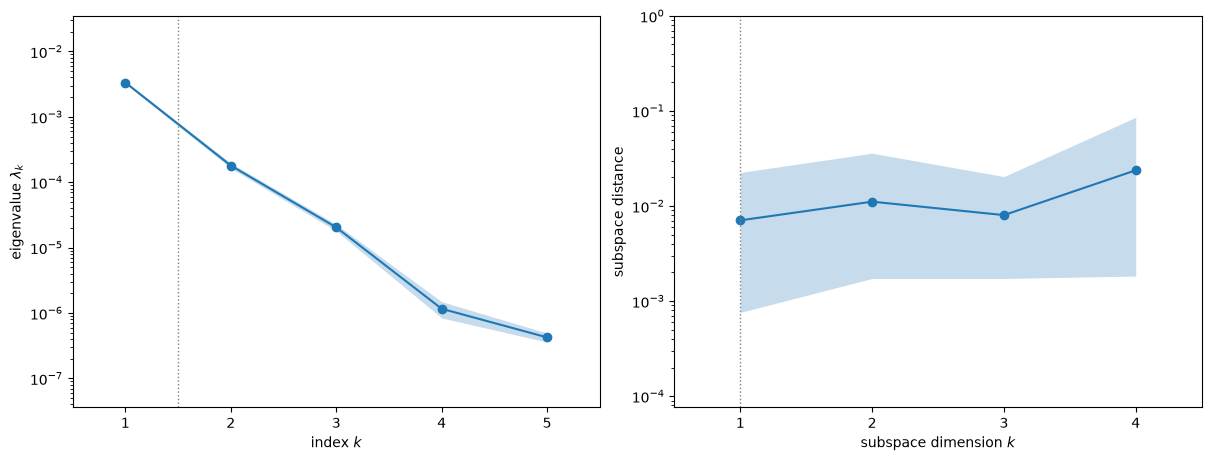

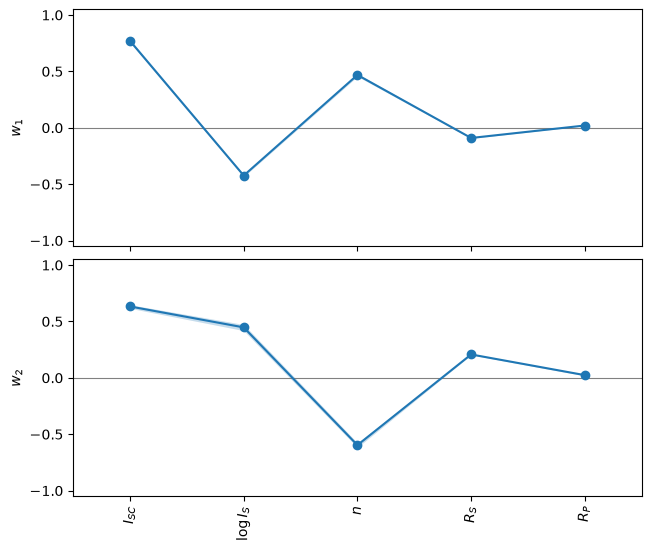

In [6]:
sample = rng.choice(M, size=1000, replace=False)
sub = ac.active_subspace(grads=G_phys[sample], space=space, nboot=1000, bootstrap_vectors=2, rng=rng)
sub = ac.orient(sub, by='reference', reference=first_positive, columns=2)

lam_box = ac.bootstrap_interval(np.abs(sub.bootstrap_eigenvalues), level=0.99)
dist = ac.mean_distance(sub)
print(f'M = 1000 samples, 1000 replicates, 99% intervals; dimension n = {sub.n}')
print(' k   eigenvalue   interval                  mean subspace distance')
for k in range(m):
    d = f'{dist[k]:.1e}' if k < m - 1 else ''
    print(f' {k+1}   {sub.eigenvalues[k]:.3e}    [{lam_box[0, k]:.3e}, {lam_box[1, k]:.3e}]   {d}')
for j in range(2):
    box = ac.bootstrap_interval(sub.bootstrap_eigenvectors[:, :, j], level=0.99)
    print(f'w_{j+1} =', np.array2string(sub.W[:, j], precision=4),
          f'widest 99% interval of a component {np.max(box[1] - box[0]):.3f}')

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), layout='constrained')
ac.plotting.plot_eigenvalues(sub, interval='percentile', level=0.99, ax=axes[0])
ac.plotting.plot_subspace_errors(sub, interval='percentile', level=0.99, ax=axes[1])

fig, axes = plt.subplots(2, 1, sharex=True, figsize=(6.4, 5.4), layout='constrained')
ac.plotting.plot_eigenvectors(sub, indices=[0, 1], interval='percentile', level=0.99, ax=axes,
                              labels=['$I_{SC}$', '$\\log I_S$', '$n$', '$R_S$', '$R_P$']);

We can see a large (order of magnitude) difference between the first and second eigenvalues; this indicates that there could be a 1-dimensional active subspace. With all 10,000 samples, $\lambda_1/\lambda_2 = 19.4$ and $\lambda_2/\lambda_3 = 8.0$, consistent with the paper's "gap of nearly an order of magnitude between both the first and second and the second and third" eigenvalues ([[1]][R1] p. 269). With $M = 1000$ samples the bootstrap intervals are already tight, and the mean subspace distance for $n = 1$, $7.1\times 10^{-3}$, is of the same size as in [[1]][R1] Figure 2b. With all 10,000 samples they are tighter still: the widest min/max range of a $\mathbf w_1$ component over 500 replicates is 0.0088, and the mean subspace distance for $n = 1$ is $2.2\times 10^{-3}$.

<br>

Plot the quantity of interest, $P_{max}$, against the active variables ($\mathbf W_1^T\mathbf x$, with $\mathbf W_1$ from all 10,000 samples), for one and two-dimensional subspaces (see also Figure 4 of [[1]][R1], which shows 100 samples; here all 10,000 are shown).

[R1]: https://doi.org/10.1002/sam.11281

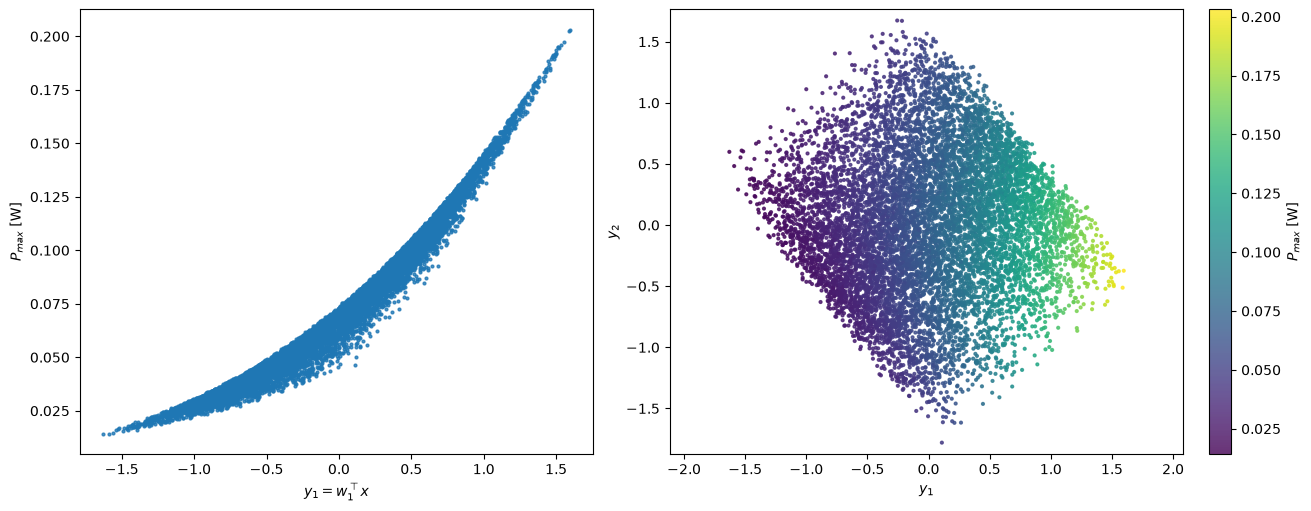

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5), layout='constrained')
for ax, dims in zip(axes, (1, 2)):
    ac.plotting.plot_sufficient_summary(sub_all, X=Xt, f=f, dims=dims, qoi_label='$P_{max}$ [W]',
                                        ax=ax, scatter_kw={'s': 4})

We can see a fairly tight univariate trend in the first graph of $P_{max}$ vs. the first active variable, and $P_{max}$ in the 2-d plot varies primarily along the axis of the first active variable. These facts indicate we have a one-dimensional active subspace that can be exploited for parameter studies.

<br>

We'll now examine the components of the first eigenvector, $\mathbf w_1$, that defines the direction of our active subspace, beside the 2016 notebook's values and [[1]][R1] Table 2, which also lists Sobol' indices. The $I_S$ component is with respect to the normalized $\log I_S$.

[R1]: https://doi.org/10.1002/sam.11281

In [8]:
table2 = {'w_1': [0.77, -0.42, 0.47, -0.09, 0.02], 'first': [0.56, 0.17, 0.21, 0.01, 0.00],
          'total': [0.61, 0.19, 0.25, 0.01, 0.00]}   # [1] Table 2
print(f'{"variable":10}{"w_1":>9}{"2016":>9}{"paper w_1":>11}{"Sobol first":>13}{"Sobol total":>13}')
for k, name in enumerate(space.names):
    print(f'{name:10}{sub_all.W[k, 0]:9.4f}{w1_2016[k]:9.4f}{table2["w_1"][k]:11.2f}'
          f'{table2["first"][k]:13.2f}{table2["total"][k]:13.2f}')

variable        w_1     2016  paper w_1  Sobol first  Sobol total
I_SC         0.7674   0.7674       0.77         0.56         0.61
log I_S     -0.4228  -0.4228      -0.42         0.17         0.19
n            0.4730   0.4730       0.47         0.21         0.25
R_S         -0.0906  -0.0906      -0.09         0.01         0.01
R_P          0.0207   0.0207       0.02         0.00         0.00


A component with a large magnitude indicates the output is relatively sensitive to changes in the corresponding variable. Since $R_S$ and $R_P$ have components close to 0, they tend not to affect output much compared to $I_{SC}$, $I_S$, and $n$. The high weight on $I_{SC}$ can be explained by the physics of the system; for the maximizer of power, $(I_{max}, V_{max})$, $I_{max}$ scales linearly with $I_{SC}$ and $V_{max}$ scales logarithmically, so their product scales like a product of a linear term and a logarithmic term. The dependence of both $I_{max}$ and $V_{max}$ on $I_{SC}$ explains its importance in the active subspace. It is also possible that the chosen parameter ranges have made $R_S$ and $R_P$ appear unimportant; the ranges for these variables used in the simulation are smaller than what would be observed in practice while the other ranges are representative of reality ([[1]][R1] §4.5). Widening the ranges of $R_S$ and $R_P$ could increase their importance in the active subspace.

When computing first-order and total sensitivity Sobol' indices on this system (see Table 2 of [[1]][R1]), we find that these metrics also rank $I_{SC}$, $I_S$, and $n$ as important and $R_S$ and $R_P$ as unimportant. Despite the similar conclusions regarding individual variables, the application of the two methods is different. From the Sobol' indices, one might set $R_S$ and $R_P$ at nominal values and perform parameter studies using only the other 3 parameters, resulting in overall dimension reduction of 5D to 3D, while the active subspace exploits a _single_ direction in the input space that takes the dimensionality all the way down to 1D.

### Using Active Subspaces

There are several ways in which one could use the 1-dimensional active subspace of this system to aid parameter studies. It aids in data visualization since it takes a 5-dimensional input space that is impossible to plot down to a 1 or 2-dimensional space for which plotting is easy. The 1-dimensional structure can be used in optimization problems that would be difficult to implement in 5 dimensions. The tightness of the data in the active subspace lends itself to constructing response surfaces to approximate the map from inputs to output. Computing an integration-based average of $P_{max}$ could be made much easier in the single active direction opposed to the full 5D input space. Lastly, the active subspace can be used to find ranges of input values that constrain the output to fall within a certain range.

As an example of a response surface, we fit polynomials in the first active variable $y_1 = \mathbf w_1^T\mathbf x$ to the 10,000 samples by least squares, and report their leave-one-out $R^2$. The cubic is drawn over the sufficient summary plot.

[R1]: https://doi.org/10.1002/sam.11281

degree 1: leave-one-out R^2 = 0.938
degree 2: leave-one-out R^2 = 0.980
degree 3: leave-one-out R^2 = 0.981


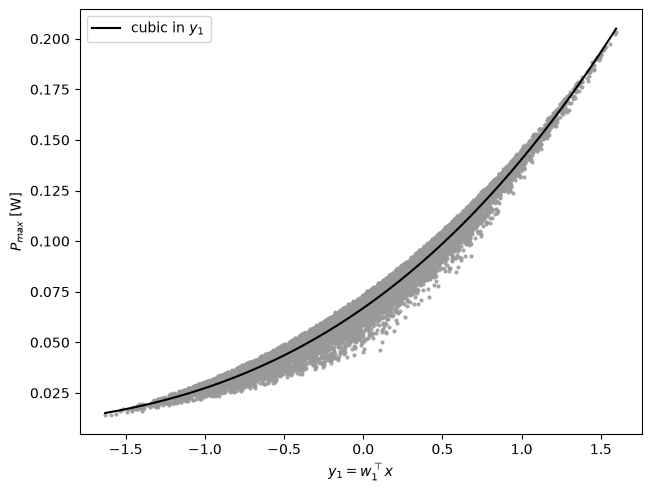

In [9]:
for degree in (1, 2, 3):
    rs = ac.fit_surrogate(X=Xt, f=f, subspace=sub_all, kind='poly', degree=degree)
    print(f'degree {degree}: leave-one-out R^2 = {rs.loo_r_squared:.3f}')

fig, ax = plt.subplots(figsize=(6.4, 4.8), layout='constrained')
ac.plotting.plot_sufficient_summary(sub_all, X=Xt, f=f, dims=1, qoi_label='$P_{max}$ [W]', ax=ax,
                                    scatter_kw={'s': 4, 'color': '0.6'})
y1 = Xn @ sub_all.W[:, 0]
y = np.linspace(y1.min(), y1.max(), 200)[:, None]
ax.plot(y, rs.evaluate(y), 'k-', label='cubic in $y_1$')
ax.legend();

A linear fit misses the curvature of the trend ($R^2 = 0.938$); the quadratic and the cubic capture it ($R^2 = 0.980$ and $0.981$), and adding the third degree gains little. The remaining scatter is the variation of $P_{max}$ along the inactive directions.

In [10]:
print(f'Total run time: {time.perf_counter() - t_start:.0f} s')

Total run time: 6 s
